# 07d · 3트랙 종합 "임팩트 분석"  (synthesis impact)

> 세 텍스트 표현 트랙(**① seed TF‑IDF · ② fastText 확장 · ③ dense KURE‑v1**, cosine·supervised)의 **기존 산출물 위에서만** 수행하는 종합 분석.
> 개별 트랙 재실행·재인코딩 없음. 통일 통제 = {길이 log(II+IV+VI 문자수), 규모 log 자산} + 업종(기준 1차금속) + 연도(기준 2022), z(ddof=0), 기업(stock_code) cluster SE. **인과 주장 금지(연관/예측).**

**이미 확정된 핵심 결론(새로 만들지 않고 정량·사례로 살린다):**
> 사업보고서 ESG 서술과 ESG 등급의 연관은 대부분 **공시 분량**과 **기업 규모(log 자산)**에서 온다. 분량·규모·업종·연도를 통제하면 텍스트–등급 연관은 약~null로 줄고, **규모가 1차 지배 예측자**다. 통제 후 살아남는 텍스트 차원은 표현마다 다르다 — **① seed=G(0.38\*\*) / ② 확장=없음 / ③ cosine=없음(E 시사·비강건) / ③ supervised=S(0.55\*)**. 신호는 차원특정이 아니라 단일 "공시 충실도" 요인에 가깝다.

**구성**: 분석 1~7, 각 ① 시각화 ② 샘플(실제 케이스) ③ 비전공자용 해석.
**엔진**: `analysis/07d_synthesis.py`(+`synth_lib.py`). 본 노트북은 그 검증된 엔진의 산출물(표 `data/processed/07d_*.csv`·그림 `reports/figures/07d_*.png`)을 보고 형식으로 정리한다. 종합 서술은 `종합_기록.md`.


In [1]:
import sys, pandas as pd
sys.path.insert(0, "/Users/home1/esg-dart-project/analysis")
from synth_lib import (load_synthesis, fit_ordered, TEXT_COLS,
                       LEN_Z, SIZE_Z, SECTOR_DUMMIES, YEAR_DUMMIES, DP, FIG)
from IPython.display import Image, display
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

def show_fig(name): display(Image(filename=f"{FIG}/07d_{name}.png"))
def show_tbl(name, n=None):
    df = pd.read_csv(f"{DP}/07d_{name}.csv")
    display(df if n is None else df.head(n)); return df

# 종합 테이블(=3트랙 1:1 병합) 로드 + 무결성
m = load_synthesis()
assert len(m) == 381 and m[TEXT_COLS].isna().sum().sum() == 0
print("종합 테이블 07d_synthesis_table.csv:", m.shape, "| 결측 0 · 381행 OK")

종합 테이블 07d_synthesis_table.csv: (381, 50) | 결측 0 · 381행 OK


### 엔진 신뢰성 검증 (committed 05b 수치 복원)
종합의 모든 회귀는 이 엔진으로 돌린다. 먼저 **트랙 ①의 committed 값을 정확히 복원**하는지 확인한다(복원되면 dense·확장에 적용해도 신뢰 가능 — 통일 스펙·동일 데이터이므로).

In [2]:
# seed-G 완전통제 매칭 계수: committed 0.378** 복원?
r = fit_ordered(m, "g_grade", ["tfidf_G_z", LEN_Z, SIZE_Z] + SECTOR_DUMMIES + YEAR_DUMMIES)
print(f"seed-G 완전통제 계수 = {r['params']['tfidf_G_z']:.4f}  (committed 0.378),  p = {r['pvals']['tfidf_G_z']:.4f}")
ri = fit_ordered(m, "esg_grade_num",
                 ["tfidf_E_z","tfidf_S_z","tfidf_G_z",LEN_Z,SIZE_Z]+SECTOR_DUMMIES+YEAR_DUMMIES)
print(f"통합 log_assets_z 계수 = {ri['params'][SIZE_Z]:.3f} (committed 1.062), "
      f"tfidf_G_z = {ri['params']['tfidf_G_z']:.3f} (committed 0.458)  ← 규모가 텍스트보다 지배")

seed-G 완전통제 계수 = 0.3780  (committed 0.378),  p = 0.0034


통합 log_assets_z 계수 = 1.062 (committed 1.062), tfidf_G_z = 0.458 (committed 0.458)  ← 규모가 텍스트보다 지배


---
## 분석 1 ⭐⭐⭐ 위계적 R² 증분 — 텍스트의 점증적 설명력은 작다
**왜**: "통제 후 비유의"보다 "규모+분량+산업이 등급 변동의 X%를 설명하고, 텍스트를 더해도 +Y%p뿐"이 자동 스코어링의 한계를 가장 설득력 있게 보여준다. **무엇**: 통합등급에 블록 누적(절편→+규모→+분량→+산업→+연도→+텍스트), ⑥의 텍스트만 4 표현으로 교체해 ΔR²를 비교(OLS R² + 순서형 McFadden).

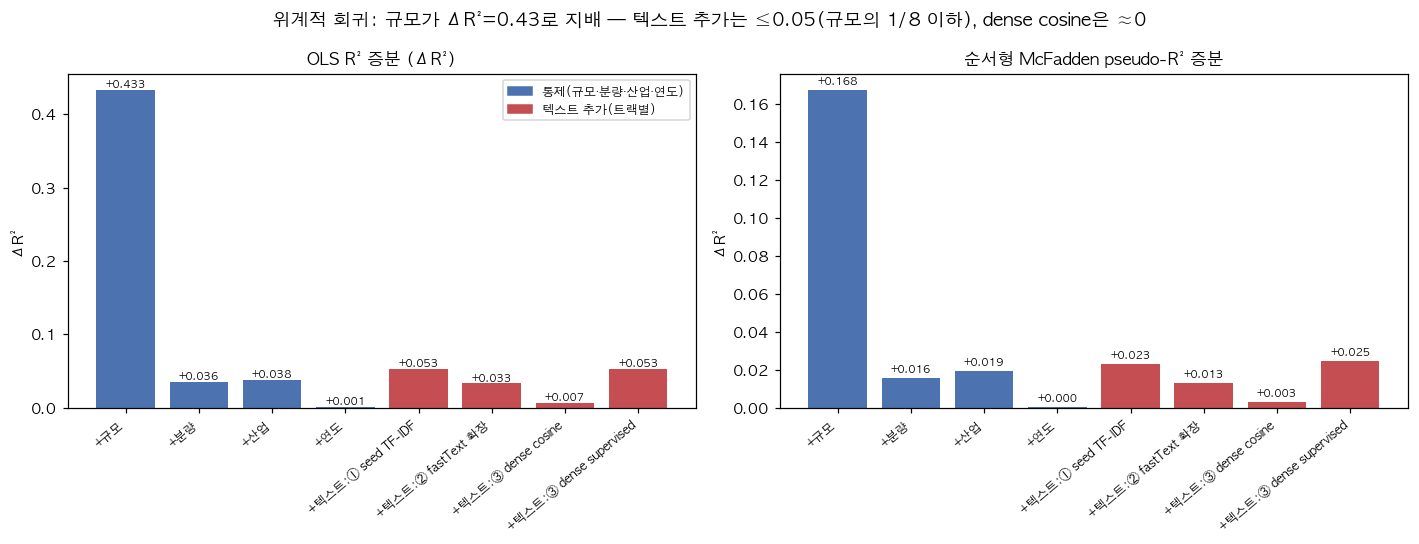

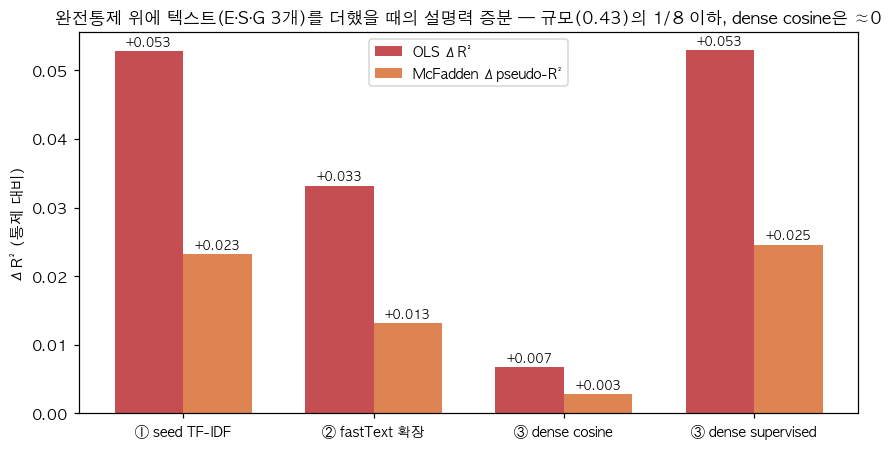

,block,kind,ols_r2,ols_dr2,mcfadden,mcf_dr2
0,+규모,통제,0.4332,0.4332,0.1676,0.1676
1,+분량,통제,0.4689,0.0357,0.1833,0.0157
2,+산업,통제,0.5065,0.0376,0.2025,0.0192
3,+연도,통제,0.5073,0.0008,0.2028,0.0004
4,+텍스트:① seed TF-IDF,텍스트,0.5602,0.0528,0.2260,0.0232
5,+텍스트:② fastText 확장,텍스트,0.5405,0.0332,0.2159,0.0131
6,+텍스트:③ dense cosine,텍스트,0.5140,0.0067,0.2057,0.0028
7,+텍스트:③ dense supervised,텍스트,0.5603,0.0529,0.2274,0.0246


In [3]:
show_fig("a1_block_increments"); show_fig("a1_text_deltaR2"); _=show_tbl("a1_hierarchical_r2")

**③ 해석(비전공자용)**: 회사 **규모(자산) 하나만으로 ESG 통합등급 변동의 43%(OLS R²)** 가 설명된다 — 큰 회사일수록 등급이 높다는 구조적 사실이다. 거기에 분량·산업·연도를 더해도 50%까지 오른다. 그런데 그 위에 **E·S·G 텍스트 점수 3개를 통째로 더해도 설명력은 0.7%p(dense cosine)~5.3%p(seed/supervised)밖에 안 늘어난다** — 규모 한 변수의 1/8 이하다. 즉 "사업보고서에 ESG를 어떻게/얼마나 썼는가"는 등급을 거의 추가 설명하지 못하며, 이는 어떤 텍스트 표현을 써도 마찬가지다. seed·supervised의 5%p는 노이즈(약 0.8%p)보다는 크지만(주로 seed=G, supervised=S 한 차원), 규모의 압도적 설명력 앞에서는 미미하다. → **자동 텍스트 ESG 스코어링은 규모를 못 이긴다.**

---
## 분석 2 ⭐⭐⭐ 잔차 분석 — "공시량 대비 등급" 사분면 + 과대공시 후보
**왜**: 연구를 "null 보고"에서 "실무 진단 도구"로 격상. 선행연구의 "그린워싱 기업이 길게 쓴다"를 우리는 **공시량·규모·산업으로 예측한 등급과의 불일치(잔차)** 로 식별한다. **무엇**: 텍스트 없이 규모+분량+산업으로 등급을 예측 → 잔차. 잔차 최저=공시·규모 대비 저평가(과대공시 의심), 최고=효율 공시. **단정 금지·중립 라벨·익명/집계 병행.**

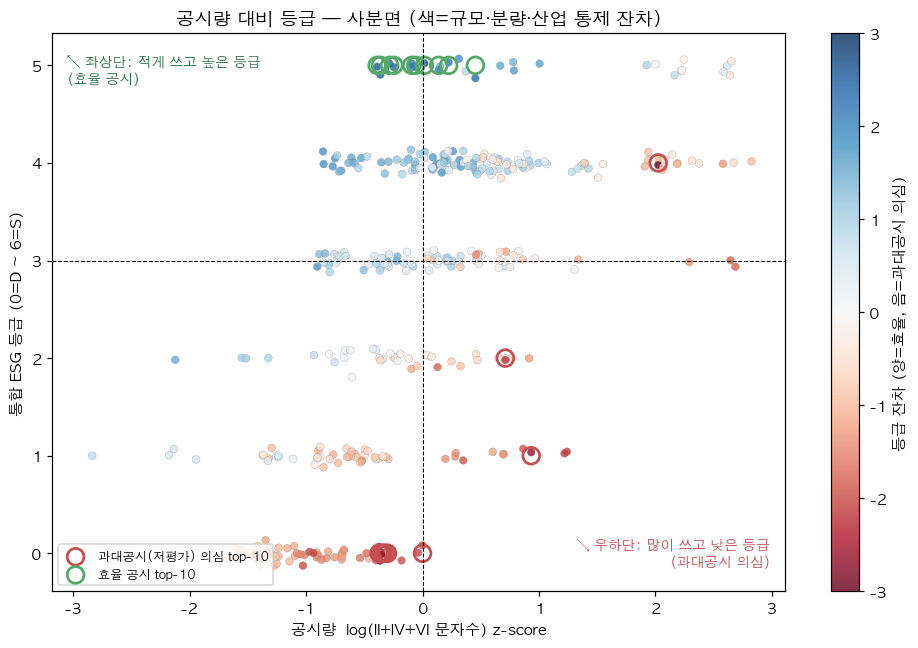

▶ 과대공시(저평가) 의심 / 효율 공시 후보 (익명화):


,anon_id,sector,size_bucket,esg_grade,esg_grade_num,log_assets,log_core_doc_len,log_core_doc_len_z,resid,tfidf_E,tfidf_S,tfidf_G,expanded_tfidf_E,expanded_tfidf_S,expanded_tfidf_G,E_cos,S_cos,G_cos,E_sup,S_sup,G_sup,label
0,대형 금융·보험사 A,금융·보험,대형,A,4,46.366,12.348,2.024,-4.496,0.019,0.069,0.017,0.043,0.161,0.187,0.187,0.168,0.189,4.423,3.594,2.337,과대공시(저평가) 의심
1,대형 유통·물류·건설·기타사 A,유통·물류·건설·기타,대형,C,1,29.893,11.641,0.933,-2.660,0.047,0.042,0.016,0.066,0.159,0.294,0.174,0.167,0.184,2.602,3.036,2.454,과대공시(저평가) 의심
2,중형 유통·물류·건설·기타사 A,유통·물류·건설·기타,중형,D,0,28.535,10.799,-0.365,-2.603,0.032,0.134,0.008,0.063,0.247,0.119,0.285,0.248,0.259,3.409,2.472,2.148,과대공시(저평가) 의심
3,중형 유통·물류·건설·기타사 B,유통·물류·건설·기타,중형,D,0,28.472,10.807,-0.353,-2.591,0.030,0.067,0.013,0.057,0.163,0.098,0.289,0.251,0.262,3.340,2.310,2.124,과대공시(저평가) 의심
4,중형 유통·물류·건설·기타사 C,유통·물류·건설·기타,중형,D,0,28.485,10.794,-0.373,-2.585,0.033,0.161,0.009,0.093,0.311,0.129,0.287,0.248,0.261,3.175,2.305,2.244,과대공시(저평가) 의심
5,소형 유통·물류·건설·기타사 A,유통·물류·건설·기타,소형,D,0,27.433,10.841,-0.301,-2.321,0.102,0.025,0.024,0.289,0.041,0.061,0.322,0.165,0.201,1.732,2.327,2.350,과대공시(저평가) 의심
6,소형 유통·물류·건설·기타사 B,유통·물류·건설·기타,소형,D,0,27.368,10.831,-0.316,-2.294,0.105,0.020,0.026,0.311,0.026,0.078,0.329,0.167,0.274,1.635,2.214,2.232,과대공시(저평가) 의심
7,소형 유통·물류·건설·기타사 C,유통·물류·건설·기타,소형,D,0,27.302,10.817,-0.339,-2.264,0.110,0.019,0.025,0.312,0.053,0.106,0.332,0.164,0.218,1.725,2.003,2.360,과대공시(저평가) 의심
8,대형 금융·보험사 B,금융·보험,대형,B,2,33.788,11.497,0.711,-2.221,0.051,0.050,0.034,0.133,0.272,0.291,0.202,0.250,0.247,4.379,3.829,3.514,과대공시(저평가) 의심
9,소형 제약·바이오·의료사 A,제약·바이오·의료,소형,D,0,26.977,11.036,-0.001,-2.113,0.004,0.050,0.011,0.034,0.117,0.123,0.190,0.158,0.159,2.948,3.877,2.782,과대공시(저평가) 의심


In [4]:
show_fig("a2_quadrant"); print("▶ 과대공시(저평가) 의심 / 효율 공시 후보 (익명화):"); _=show_tbl("a2_candidates_anon", 20)

In [5]:
print("▶ 후보군 vs 나머지 (Mann-Whitney): 등급은 크게 다르나 텍스트·규모·분량은 안 다름"); _=show_tbl("a2_group_compare")

▶ 후보군 vs 나머지 (Mann-Whitney): 등급은 크게 다르나 텍스트·규모·분량은 안 다름


,variable,cand_mean,rest_mean,diff,mw_u,mw_p
0,log_assets,30.4620,28.8932,1.5687,1868.0,0.9710
1,log_core_doc_len,11.1412,11.0334,0.1078,2039.0,0.5934
2,esg_grade_num,0.7000,2.6496,-1.9496,690.0,0.0005
3,tfidf_E,0.0533,0.0976,-0.0443,1463.0,0.2546
4,tfidf_S,0.0638,0.0540,0.0098,2034.0,0.6035
5,tfidf_G,0.0182,0.0284,-0.0102,1601.0,0.4601
6,expanded_tfidf_E,0.1401,0.2215,-0.0814,1609.0,0.4750
7,expanded_tfidf_S,0.1551,0.1426,0.0125,2028.0,0.6157
8,expanded_tfidf_G,0.1486,0.2067,-0.0581,1286.0,0.0981
9,E_cos,0.2596,0.2378,0.0218,2248.0,0.2534


**③ 해석(비전공자용)**: 각 회사의 등급을 **텍스트는 빼고** 규모·분량·산업만으로 예측한 뒤, 실제 등급이 예측보다 얼마나 낮은지(잔차)를 본다. 잔차가 가장 음(陰)인 회사들은 "비슷한 규모·분량·업종의 다른 회사보다 등급이 현저히 낮은" **공시량 대비 저평가(과대공시 의심) 후보**다(평균 등급 0.70 vs 나머지 2.65). 반대로 잔차 최고는 "적게 쓰고도 높은 등급"의 효율 공시다. **핵심 반전**: 이 후보들을 **9개 텍스트 점수 어느 것으로도 구별할 수 없다**(Mann‑Whitney 전부 p>0.09) — 규모·분량도 차이 없음. 즉 등급 이상치는 텍스트가 포착하지 못하는 곳에서 발생한다. 이는 "그린워싱 단정"이 아니라 **공시량 대비 평가가 어긋난 기업을 찾아내는 진단 도구**다(실명은 익명/집계로 보고).

---
## 분석 3 ⭐⭐⭐ 표현 방법 간 일치/불일치 — 어느 방법도 같은 차원을 못 가른다 (종합 하이라이트)
**왜**: 이 연구의 가장 독창적 메타발견 = **"표현마다 생존 차원이 다르다(①G / ②없음 / ③E·S)"**. 진짜 강한 차원 신호가 있었다면 방법이 달라도 *같은* 차원이 살았어야 한다 → 그렇지 않다 = **안정적 차원 신호 부재**. 세 기록에 흩어진 걸 한 곳에 모은다. **무엇**: (a) 트랙 간 같은‑차원 점수 수렴, (b) 부분 3×3 대각지배 4패널, (c) 완전통제 후 자기차원 계수, (d) 차원별 생존 트랙 수.

(a) 트랙 간 텍스트 점수 수렴(12×12 Spearman) — 같은 차원도 표현 다르면 약하게만 수렴


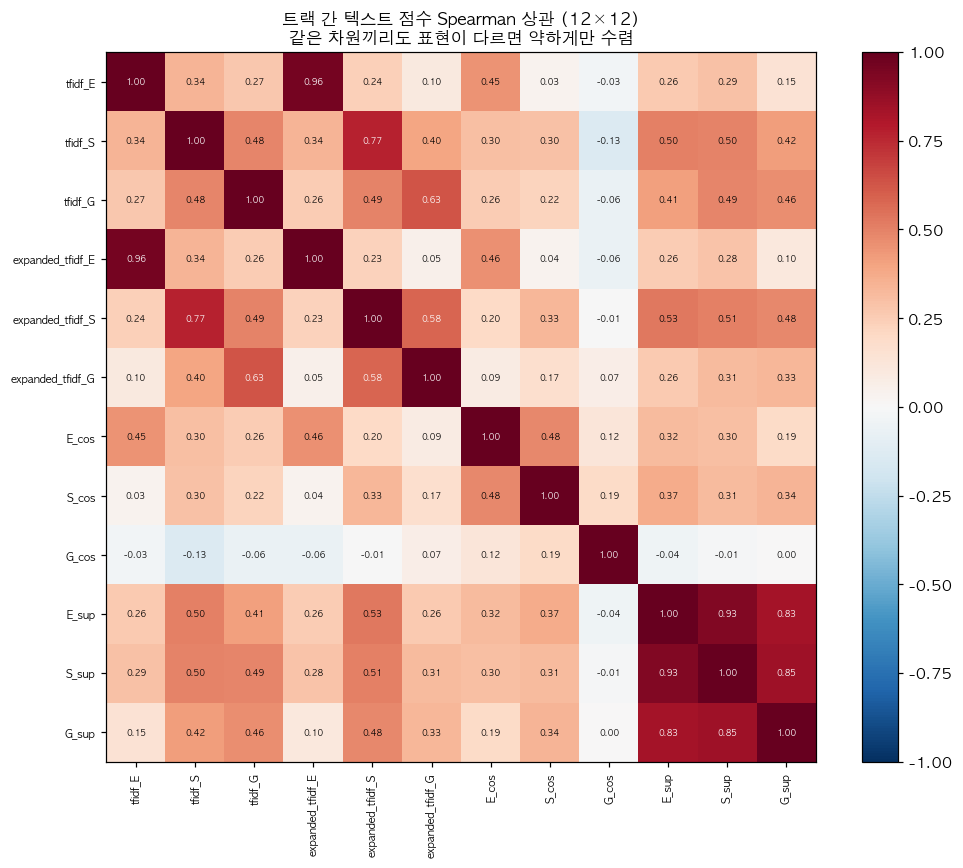

In [6]:
print("(a) 트랙 간 텍스트 점수 수렴(12×12 Spearman) — 같은 차원도 표현 다르면 약하게만 수렴"); show_fig("a3_convergence_heatmap")

(b) 부분 3×3 Spearman (길이+규모 통제) — 표현마다 대각지배 3/3·2/3·1/3·2/3


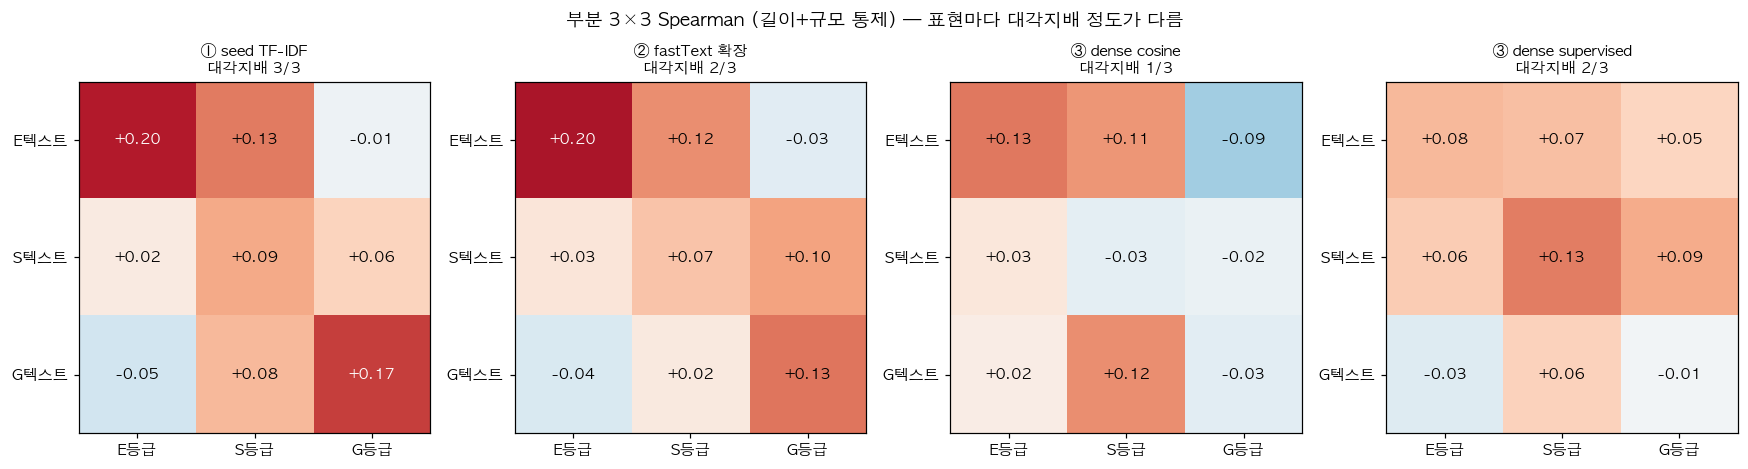

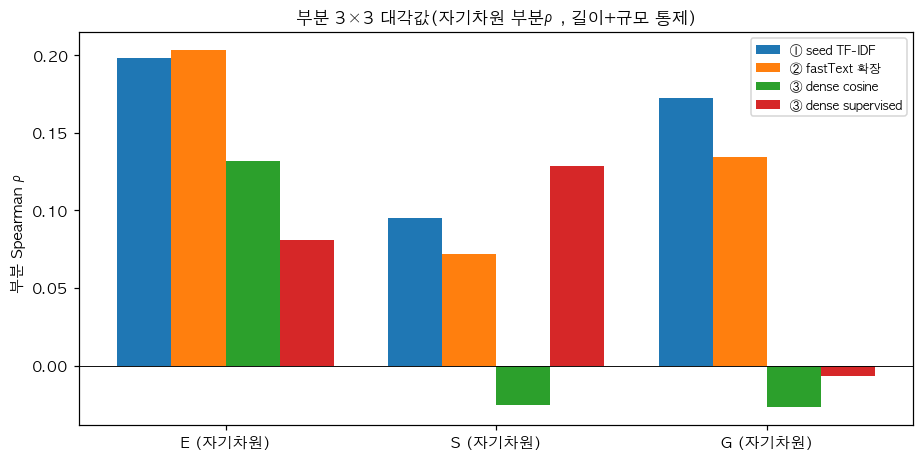

In [7]:
print("(b) 부분 3×3 Spearman (길이+규모 통제) — 표현마다 대각지배 3/3·2/3·1/3·2/3"); show_fig("a3_partial3x3_panels"); show_fig("a3_partial3x3_diagonal")

(c) 완전통제 후 자기차원 텍스트 계수


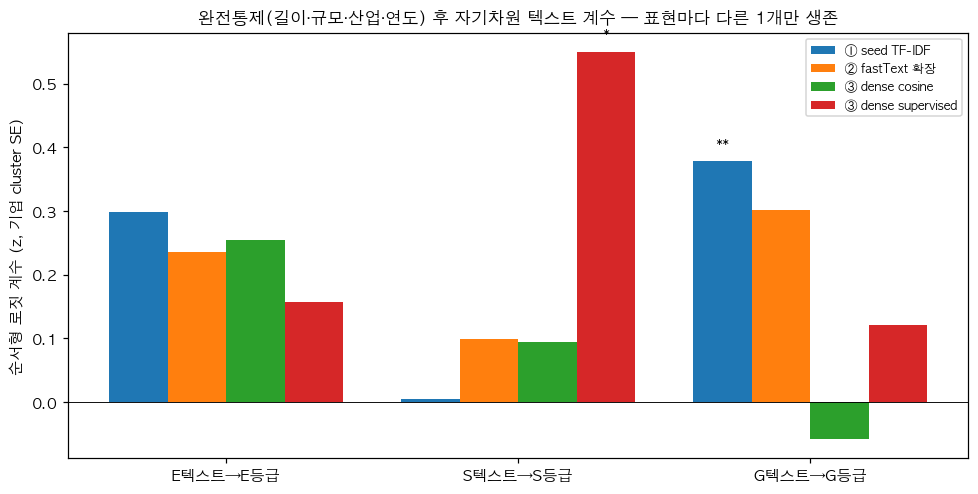

,repr,label,dim,coef,p,ci_low,ci_high,sig
0,seed_tfidf,① seed TF-IDF,E,0.2978,0.1210,-0.0786,0.6741,NaN
1,seed_tfidf,① seed TF-IDF,S,0.0043,0.9832,-0.4001,0.4088,NaN
2,seed_tfidf,① seed TF-IDF,G,0.3780,0.0034,0.1251,0.6309,**
3,expanded,② fastText 확장,E,0.2352,0.2597,-0.1738,0.6442,NaN
4,expanded,② fastText 확장,S,0.0994,0.5741,-0.2474,0.4462,NaN
5,expanded,② fastText 확장,G,0.3019,0.0858,-0.0425,0.6462,NaN
6,dense_cos,③ dense cosine,E,0.2547,0.1174,-0.0641,0.5734,NaN
7,dense_cos,③ dense cosine,S,0.0943,0.5589,-0.2218,0.4103,NaN
8,dense_cos,③ dense cosine,G,-0.0578,0.6934,-0.3455,0.2298,NaN
9,dense_sup,③ dense supervised,E,0.1570,0.4768,-0.2755,0.5895,NaN


In [8]:
print("(c) 완전통제 후 자기차원 텍스트 계수"); show_fig("a3_fullcontrol_bars"); _=show_tbl("a3_fullcontrol_coef")

In [9]:
print("(d) 메타: 차원별 생존(표현) 수 — 어느 차원도 과반(>2/4) 재현 안 됨"); _=show_tbl("a3_meta_survival")

(d) 메타: 차원별 생존(표현) 수 — 어느 차원도 과반(>2/4) 재현 안 됨


,dim,n_repr,n_survive_p05,survivors,max_coef,min_p
0,E,4,0,(없음),0.2978,0.1174
1,S,4,1,③ dense supervised,0.5499,0.0130
2,G,4,1,① seed TF-IDF,0.3780,0.0034


**③ 해석(비전공자용)**: 같은 "환경(E)" 점수라도 **표현 방법이 다르면 같은 회사를 가리키지 않는다.** 전혀 다른 두 방법(단어빈도 TF‑IDF vs 의미임베딩 dense)의 같은‑차원 수렴은 E 0.45·S 0.30·**G −0.06**(G는 정반대!)에 그친다. 완전통제 후 "자기 차원 등급"을 예측하는 텍스트는 — **① seed는 G만, ② 확장은 아무것도, ③ dense cosine은 아무것도(E 시사적이나 비강건), ③ supervised는 S만** 살아남는다. 차원별로 "몇 개 표현에서 살아남았나"를 세면 **E 0개 · S 1개 · G 1개(4개 중)** — 어느 차원도 과반에서 재현되지 않는다. 만약 "환경 서술이 환경 등급을, 지배구조 서술이 지배구조 등급을 따로 잰다"가 진짜라면 방법이 달라도 같은 차원이 살아야 한다. 그렇지 않다는 것은 **텍스트–등급 연관이 차원특정 신호가 아니라 단일 '공시 충실도' 요인에 가깝다**는 강한 증거다.

---
## 분석 4 ⭐⭐ "긴 보고서 = 좋은 등급" 통념의 직접 검정·반박
**왜**: 선행연구(중국 10,021개 보고서)의 "보고서 길이·완전성이 ESG 점수에 유의"를 정교하게 반박. 길이가 **기업 규모의 대리**임을 보인다(트랙 무관, 통제변수만). **무엇**: raw 상관 → 규모 통제 부분상관 → 규모 매개 분해 → 길이 정의(문자수/문장수) robustness.

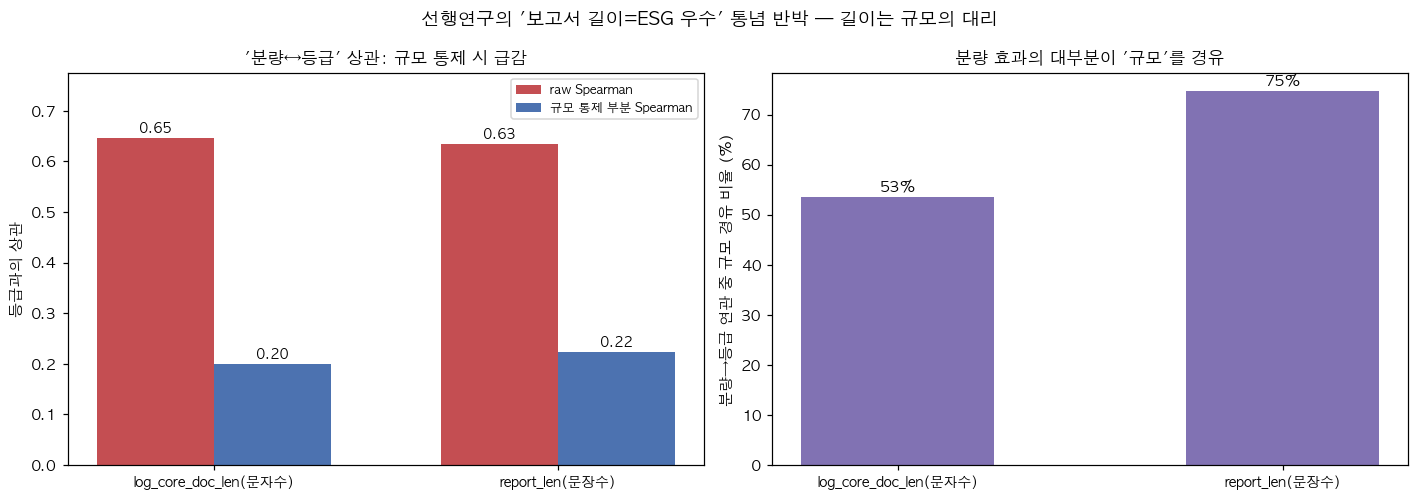

,length_def,spearman_raw,pearson_raw,partial_spearman_ctrl_size,drop,coef_total,coef_direct,pct_via_size
0,log_core_doc_len(문자수),0.6460,0.6224,0.2000,0.4460,1.0091,0.4701,0.5342
1,report_len(문장수),0.6341,0.4920,0.2236,0.4105,0.7976,0.2026,0.7461


In [10]:
show_fig("a4_length_myth"); _=show_tbl("a4_length_myth")

**③ 해석(비전공자용)**: 보고서 길이와 ESG 등급의 단순 상관은 **0.65**로 매우 커 보인다 — 선행연구가 "길게 쓰면 ESG가 좋다"고 해석한 바로 그 수치다. 그러나 **기업 규모(자산)를 통제하면 0.20으로 급감**하고, 길이가 등급과 갖는 연관의 **53~75%가 규모를 경유**한다. 즉 "긴 보고서 = 좋은 ESG"가 아니라 "**큰 회사 = 길게 쓰고 동시에 등급도 높다**"이며, 길이 자체의 고유 효과는 작다. 보고서 길이를 ESG 품질 지표로 쓰면 사실상 회사 크기를 재게 된다.

---
## 분석 5 ⭐⭐ 산업 효과 정밀화 — 산업이 등급의 주요 결정요인
**왜**: 세 트랙 통합 회귀 모두에서 산업더미(특히 IT·통신·미디어)가 텍스트의 10배 넘는 지배 변수. 기준(1차금속, n=18)이 작아 해석 불안정 → 편차(sum‑to‑zero) 코딩으로 정밀화하고, 산업 내에서도 텍스트가 죽는지 본다. **무엇**: (a) 산업 프로파일, (b) 전체평균 대비 편차효과 + 산업‑only 설명력, (c) 산업 within 텍스트 부분상관.

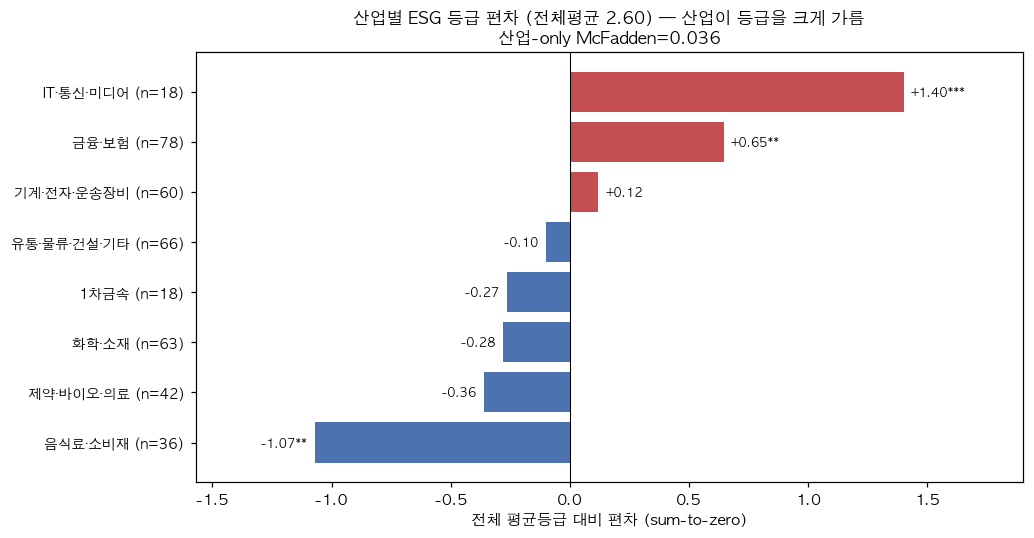

▶ 산업 프로파일(등급 내림차순)


,sector,n,mean_grade,mean_log_assets,mean_log_core_len,mean_tfidf_E,mean_tfidf_S,mean_tfidf_G,mean_expanded_tfidf_E,mean_expanded_tfidf_S,mean_expanded_tfidf_G,mean_E_cos,mean_S_cos,mean_G_cos,mean_E_sup,mean_S_sup,mean_G_sup
0,IT·통신·미디어,18,4.000,30.428,11.307,0.067,0.048,0.037,0.120,0.140,0.188,0.263,0.204,0.290,3.679,4.563,3.467
1,금융·보험,78,3.244,30.658,11.395,0.048,0.045,0.034,0.108,0.157,0.288,0.203,0.187,0.233,3.237,3.696,2.836
2,기계·전자·운송장비,60,2.717,28.910,10.860,0.142,0.069,0.025,0.322,0.150,0.172,0.279,0.178,0.248,3.061,3.468,2.298
3,유통·물류·건설·기타,66,2.500,28.129,10.816,0.088,0.054,0.027,0.188,0.131,0.186,0.222,0.199,0.232,2.718,3.029,2.215
4,1차금속,18,2.333,28.963,11.133,0.235,0.069,0.039,0.563,0.149,0.214,0.311,0.186,0.214,2.324,2.440,1.732
5,화학·소재,63,2.317,28.858,11.157,0.140,0.067,0.025,0.341,0.177,0.181,0.246,0.206,0.245,2.967,3.472,2.435
6,제약·바이오·의료,42,2.238,27.531,10.993,0.040,0.034,0.027,0.086,0.092,0.147,0.210,0.173,0.228,2.139,2.644,2.064
7,음식료·소비재,36,1.528,27.727,10.610,0.078,0.049,0.019,0.166,0.122,0.232,0.249,0.165,0.230,2.556,2.814,1.671


In [11]:
show_fig("a5_industry_effects"); print("▶ 산업 프로파일(등급 내림차순)"); _=show_tbl("a5_industry_profile")

In [12]:
print("▶ 산업 within 자기차원 부분ρ (산업+길이+규모 통제) — 산업 안에서도 텍스트는 약함"); _=show_tbl("a5_within_industry_text")

▶ 산업 within 자기차원 부분ρ (산업+길이+규모 통제) — 산업 안에서도 텍스트는 약함


,repr,label,dim,partial_rho_industry_only,partial_rho_industry_len_size
0,seed_tfidf,① seed TF-IDF,E,0.462,0.189
1,seed_tfidf,① seed TF-IDF,S,0.404,0.071
2,seed_tfidf,① seed TF-IDF,G,0.455,0.149
3,expanded,② fastText 확장,E,0.475,0.206
4,expanded,② fastText 확장,S,0.416,0.073
5,expanded,② fastText 확장,G,0.325,0.168
6,dense_cos,③ dense cosine,E,0.347,0.100
7,dense_cos,③ dense cosine,S,0.186,-0.015
8,dense_cos,③ dense cosine,G,-0.051,-0.047
9,dense_sup,③ dense supervised,E,0.513,0.042


**③ 해석(비전공자용)**: ESG 등급은 **산업에 따라 체계적으로 다르다.** IT·통신·미디어(평균 4.0=A)와 음식료·소비재(1.5)는 약 2.5등급 차이로, 전체평균 대비 편차가 각각 +1.40\*\*\*·−1.07\*\*로 유의하다(금융·보험 +0.65\*\*도). 산업더미만으로 통합등급 변동의 12%(OLS)를 설명한다 — 규모 다음의 2차 결정요인이다. 더 중요한 건, **같은 산업 안에서 비교해도 텍스트–등급 연관은 여전히 약하다**(seed G 0.15, 나머지 대부분 <0.1). 즉 "고등급 산업이 마침 ESG를 잘 써서"가 아니라, 산업·규모 같은 구조적 요인이 등급을 주로 가르고 텍스트의 자리는 좁다.

---
## 분석 6 ⭐ 약신호의 정밀도 — 부트스트랩 CI·순열검정 통일
**왜**: 트랙 ①은 이미 부분 대각 ρ에 부트스트랩 CI·순열검정을 적용했다(`TF‑IDF_기록.md §12.2b`). **공정 비교를 위해 ②·③의 생존 차원에도 동일 잣대**를 적용한다. "CI 0 제외 ≠ 중요" 원칙을 종합 전체에 일관 적용. **무엇**: 핵심 신호별 부분 Spearman + 행부트(381)·**기업부트(127, 보수적)** 95% CI + 순열검정(N=10,000, seed 고정).

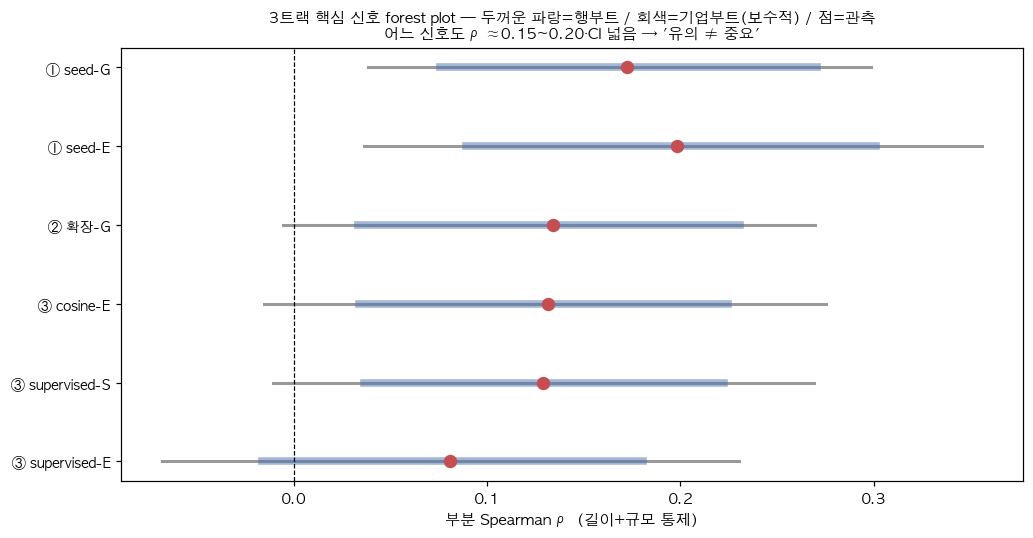

,signal,text_col,grade,obs_partial_rho,row_ci_lo,row_ci_hi,firm_ci_lo,firm_ci_hi,perm_p,firm_excl0,matched_coef,matched_p,matched_sig,matched_ci_lo,matched_ci_hi,effect,verdict
0,① seed-G,tfidf_G,g_grade,0.1726,0.0756,0.2705,0.0382,0.2987,0.0012,True,0.3780,0.0034,**,0.1251,0.6309,약,기업부트 0제외(견고)
1,① seed-E,tfidf_E,e_grade,0.1983,0.0892,0.3014,0.0365,0.3560,0.0001,True,0.2978,0.1210,NaN,-0.0786,0.6741,약,기업부트 0제외(견고)
2,② 확장-G,expanded_tfidf_G,g_grade,0.1342,0.0330,0.2306,-0.0055,0.2697,0.0108,False,0.3019,0.0858,NaN,-0.0425,0.6462,약,행부트 0제외·기업부트 0포함(경계)
3,③ cosine-E,E_cos,e_grade,0.1316,0.0339,0.2246,-0.0154,0.2751,0.0096,False,0.2547,0.1174,NaN,-0.0641,0.5734,약,행부트 0제외·기업부트 0포함(경계)
4,③ supervised-S,S_sup,s_grade,0.1287,0.0362,0.2227,-0.0106,0.2689,0.0136,False,0.5499,0.0130,*,0.1159,0.9838,약,행부트 0제외·기업부트 0포함(경계)
5,③ supervised-E,E_sup,e_grade,0.0810,-0.0165,0.1804,-0.0680,0.2302,0.1126,False,0.1570,0.4768,NaN,-0.2755,0.5895,약,0 포함(비유의)


In [13]:
show_fig("a6_forest"); _=show_tbl("a6_signal_ci")

**③ 해석(비전공자용)**: 세 트랙의 "살아남은" 신호를 **하나의 자(尺)** 로 다시 잰다. 결과는 어느 것도 강하지 않다 — 모두 **ρ≈0.13~0.20(약효과)**, CI 폭이 넓다. 같은 회사의 3개 연도 의존성을 반영한 **보수적 기업부트스트랩에서 0을 확실히 벗어나는 건 seed의 E·G뿐**이고, fastText‑G·dense cosine‑E·dense supervised‑S는 모두 기업부트 하한이 0 아래로 내려가 **경계**다. 특히 dense의 supervised‑S는 회귀계수는 0.55\*로 유의하지만, 같은 부분상관 잣대로는 ρ=0.13에 기업CI가 0을 포함한다 — **"한 모형에서 유의 ≠ 중요·정밀"**. n=381·기업 127의 한계 안에서, 세 트랙 모두 "우연 수준을 약간 넘는" 정도의 신호만 갖는다.

---
## 분석 7 ⭐ G 차원 측정 종합 — 같은 G인데 표현마다 정반대
**왜**: G가 가장 흥미로운 분기점. ① TF‑IDF는 **G만 강건**, ③ dense는 **G가 최악**(개념이 E·S와 얽힘), ② 확장은 경계. "같은 G인데 방법 따라 정반대"는 강한 메타 메시지 + 투자자 함의(G를 텍스트로 잴 거면 사전 기반, 임베딩은 부적합). **무엇**: 트랙별 G 계수·부분ρ·트랙간 G 수렴 종합.

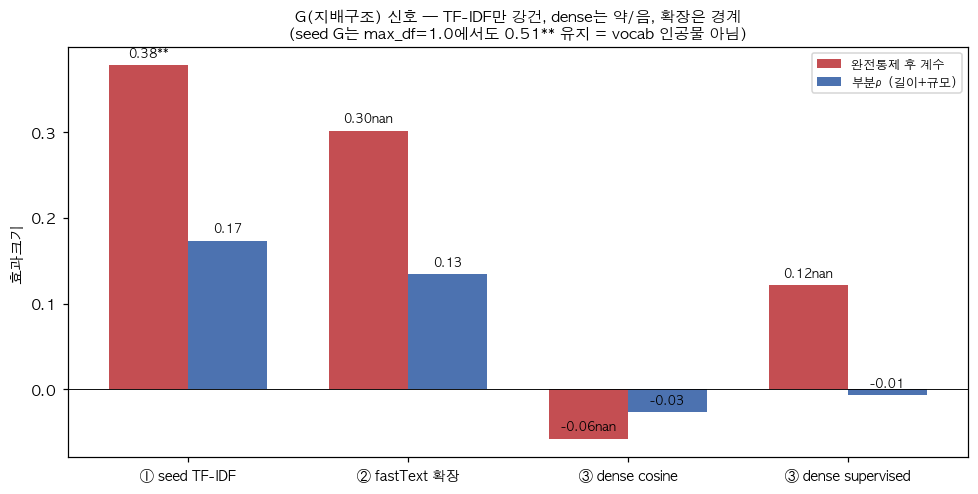

▶ G 종합(트랙×지표)


,repr,label,g_coef_fullctrl,g_coef_p,g_coef_sig,g_partial_rho
0,seed_tfidf,① seed TF-IDF,0.3780,0.0034,**,0.173
1,expanded,② fastText 확장,0.3019,0.0858,NaN,0.134
2,dense_cos,③ dense cosine,-0.0578,0.6934,NaN,-0.027
3,dense_sup,③ dense supervised,0.1211,0.5871,NaN,-0.007


▶ 트랙 간 G 수렴(Spearman)


,repr_a,repr_b,spearman
0,seed_tfidf,expanded,0.627
1,seed_tfidf,dense_cos,-0.063
2,seed_tfidf,dense_sup,0.462
3,expanded,dense_cos,0.068
4,expanded,dense_sup,0.334
5,dense_cos,dense_sup,0.003


In [14]:
show_fig("a7_g_bars"); print("▶ G 종합(트랙×지표)"); _=show_tbl("a7_g_synthesis"); print("▶ 트랙 간 G 수렴(Spearman)"); _=show_tbl("a7_g_convergence")

**③ 해석(비전공자용)**: 지배구조(G)는 표현 방법에 따라 **정반대로** 측정된다. 단어사전 기반 두 방법(seed·확장)은 G에서 서로 0.63으로 잘 맞지만, **의미임베딩(dense cosine)은 누구와도 안 맞는다**(seed와 −0.06, supervised와도 0.003). 완전통제 후 seed‑G만 0.38\*\*로 강건하고(부분ρ 0.17), dense cosine‑G는 −0.06(음), supervised‑G는 0.12(n.s.)다. 이유: TF‑IDF는 "감사위원회·준법·의결권" 같은 **특수 거버넌스 용어 카운트**로 G를 잡지만, 임베딩은 *"이사회가 환경을 논의한다"* 같은 문장에서 G와 E를 뭉개 자기 정체성을 못 지킨다(`dense_기록.md`: G 앵커 대각 0.27 < 비대각 0.30). 단, seed‑G의 강건성은 vocabulary 인공물이 아니다 — `max_df=1.0`(핵심 G어 복귀)에서도 0.51\*\*로 유지된다(`TF‑IDF_기록.md §14`). **투자자·평가기관 함의: G를 텍스트로 측정하려면 사전 기반이 맞고, 범용 임베딩은 부적합하다.**

---
## 종합 — 임팩트 3대 메시지
**ⓐ 자동 ESG 텍스트 스코어링의 한계** — E·S·G 텍스트 3개를 더해도 통합등급 설명력 증분은 ≤5.3%p(dense cosine 0.7%p), 규모 한 변수(43%p)의 1/8 이하. 어떤 표현을 써도 텍스트는 규모를 못 이긴다.

**ⓑ 규모·산업 편향** — 규모(log 자산)가 모든 트랙·모형에서 1차 지배 예측자, 산업이 2차(IT·통신·미디어 vs 음식료·소비재 2.5등급 차). "긴 보고서 = 좋은 ESG"는 규모의 대리(상관 0.65→규모 통제 0.20).

**ⓒ 공시량 대비 평가 진단도구 · 표현 무관 차원 신호 부재** — 잔차로 "공시·규모 대비 저평가 후보"를 식별(단, 텍스트 9종 어느 것도 이들을 구별 못 함). 통제 후 살아남는 차원은 표현마다 다르고(①G/②없음/③E·S) 어느 차원도 과반 표현에서 재현 안 됨 → 차원특정 신호가 아니라 단일 "공시 충실도" 요인.

> 상세 서술·논문 Discussion 재료·각 분석의 [발견·수치·대상·액션·한계]는 **`종합_기록.md`** 참조.
> **한계**: n=381·기업 127·등급 끈적함 → 통계력 제약, 분위/하위군은 탐색적. 통제 관찰연구 → 인과 아님(연관/예측). cheap‑talk(공시 강도) vs 실제 성과 구분 불가.